# Étape 5 · Interprétation

Figures de la solution, données du tableau de bord, fiches régionales.

À lancer dans le projet complet (archive `05-interpretation_D1_scientist_projet-complet_v1.zip`), avec les données brutes placées comme le dit `data/raw/LISEZ-MOI.md`.

In [1]:
import os, sys, time
from pathlib import Path
from IPython.display import Image, display

racine = Path.cwd()
while not (racine / "scripts").is_dir() and racine != racine.parent:
    racine = racine.parent
os.chdir(racine)
sys.path.insert(0, "scripts")


def montrer_figures(depuis, dossiers=("analyse/figures", "analyse", "analyse/fiches"), maxi=6):
    vues = sorted((p for d in dossiers for p in Path(d).glob("*.png") if p.stat().st_mtime >= depuis), key=lambda p: p.name)
    for p in vues[:maxi]:
        print(p)
        display(Image(filename=str(p), width=760))

## 1. Figures 13 à 17

`scripts/figures_approches.py`

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

In [3]:
def fr(x, dec=1):
    s = f"{x:,.{dec}f}".replace(",", " ").replace(".", ",")
    return s

In [4]:
def header(fig, main, sub):
    fig.text(0.01, 0.985, main, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.94, sub, fontsize=9.5, color=INK2, va="top")
    fig.text(0.01, 0.01, "Source : données du Data Challenge Burkina (DGESS), 2015/16 à 2024/25. Calculs de l'équipe.",
             fontsize=7.5, color=MUTED)

In [5]:
def nowcast():
    a = pd.read_csv("analyse/P12_nowcast_ecoles.csv")
    mean = a[a.annee == "moyenne"].iloc[0]
    a = a[a.annee != "moyenne"]
    x = np.arange(len(a))
    w = 0.38
    fig, ax = plt.subplots(figsize=(9, 5.2))
    fig.subplots_adjust(top=0.80, bottom=0.13, left=0.08, right=0.97)
    ax.bar(x - w / 2, a["effectifs_persistance_%"], w, color=SERIES[0], label="« Comme l'an passé »")
    ax.bar(x + w / 2, a["effectifs_ecoles_%"], w, color=SERIES[1], label="À partir des écoles ouvertes à la rentrée")
    for xi, v1, v2 in zip(x, a["effectifs_persistance_%"], a["effectifs_ecoles_%"]):
        ax.annotate(fr(v1), (xi - w / 2, v1), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8,
                    color=INK2)
        ax.annotate(fr(v2), (xi + w / 2, v2), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8,
                    color=INK2)
    ax.set_xticks(x, a.annee)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("Erreur moyenne sur les effectifs régionaux (%)")
    ax.set_xlabel("Année prédite (pente apprise sur les années précédentes seulement)")
    ax.legend(loc="upper left", fontsize=8.5)
    header(fig, "Connaître les écoles ouvertes à la rentrée divise l'erreur par deux",
           f"Erreur moyenne sur les effectifs des 13 régions : {fr(mean['effectifs_ecoles_%'])} % contre "
           f"{fr(mean['effectifs_persistance_%'])} %. Le gain est le plus fort l'année du choc (22/23).\n"
           "Il ne vaut que pour les effectifs : sur le taux d'achèvement, aucun gain.")
    fig.savefig("analyse/figures/13_prevision_ecoles_ouvertes.png", dpi=200)
    plt.close(fig)

In [6]:
def cohorts():
    c = pd.read_csv("analyse/P12_cohortes_national.csv")
    pr = pd.read_csv("analyse/P12_projection_CM2.csv").iloc[0]
    x = list(range(len(c)))
    fig, ax = plt.subplots(figsize=(9, 5.4))
    fig.subplots_adjust(top=0.80, bottom=0.13, left=0.09, right=0.84)
    ax.plot(x, c.CP1 / 1000, color=SERIES[0], marker="o", markersize=4.5, linewidth=2, label="CP1")
    ax.plot(x, c.CM2 / 1000, color=SERIES[1], marker="o", markersize=4.5, linewidth=2.4, label="CM2")
    nx = len(c)
    ax.plot([nx - 1, nx], [c.CM2.iloc[-1] / 1000, pr.central / 1000], color=SERIES[1], linewidth=2.4, linestyle="--")
    ax.errorbar([nx], [pr.central / 1000], yerr=[[(pr.central - pr.bas) / 1000], [(pr.haut - pr.central) / 1000]],
                fmt="o", color=SERIES[1], markerfacecolor=SURFACE, markersize=6, capsize=4, linewidth=1.4)
    ax.annotate(f"25/26 : ≈ {fr(pr.central / 1000, 0)} 000\n(de {fr(pr.bas / 1000, 0)} 000 à {fr(pr.haut / 1000, 0)} 000)",
                (nx, pr.central / 1000), xytext=(10, 0), textcoords="offset points", va="center", fontsize=8.5,
                color=INK2, annotation_clip=False)
    ax.annotate("CP1", (nx - 1, c.CP1.iloc[-1] / 1000), xytext=(8, 0), textcoords="offset points", va="center",
                fontsize=9, color=SERIES[0], fontweight="bold")
    ax.annotate("CM2", (0, c.CM2.iloc[0] / 1000), xytext=(-8, 0), textcoords="offset points", va="center", ha="right",
                fontsize=9, color=SERIES[1], fontweight="bold", annotation_clip=False)
    ax.set_xticks(x + [nx], list(c.annee) + ["25/26"])
    ax.set_xlim(-0.6, nx + 0.4)
    ax.set_ylim(0, 850)
    ax.set_ylabel("Élèves (milliers), public et privé")
    header(fig, "Le nombre d'élèves en CM2 devrait remonter en 2025/26",
           "Projection : élèves de CM1 en 2024/25 (441 000) × dernier taux de passage au CM2 (86 %). Fourchette : pire et meilleur\n"
           "passage observés ; elle n'a tenu que 4 années sur 7. Hors nouveau choc, et ce n'est pas un taux d'achèvement.")
    fig.savefig("analyse/figures/14_projection_cohortes.png", dpi=200)
    plt.close(fig)

In [7]:
PRIO = {1: ("Priorité 1 : agir maintenant", "#104281"), 2: ("Priorité 2 : veille renforcée", "#3987e5"),
        3: ("Priorité 3 : consolider", "#b7d3f6")}
LABEL = {"Liptako + Soum": (0, -13, "center"), "Goulmou + Sirba + Tapoa": (-4, 10, "center"),
         "Koulsé": (6, 8, "left"), "Bankui + Sourou": (0, -13, "center"), "Yaadga": (0, 9, "center"),
         "Nakambé": (8, 0, "left"), "Tannounyan": (-8, 0, "right"), "Guiriko": (8, 2, "left"),
         "Djôrô": (4, 9, "left"), "Oubri": (-8, 0, "right"), "Nazinon": (0, 9, "center"),
         "Nando": (8, -3, "left"), "Kadiogo": (0, 9, "center")}

In [8]:
def matrix():
    m = pd.read_csv("analyse/P13_matrice_priorite_2026_27.csv")
    fig, ax = plt.subplots(figsize=(9, 6))
    fig.subplots_adjust(top=0.80, bottom=0.11, left=0.09, right=0.97)
    tap_nat = 51.6
    ax.axvline(tap_nat, color=AXIS, linewidth=1.2, linestyle="--", zorder=1)
    ax.axhline(40, color=AXIS, linewidth=1.2, linestyle="--", zorder=1)
    ax.axhline(15, color=GRID, linewidth=1.0, linestyle=":", zorder=1)
    ax.text(tap_nat + 1, 99, "Moyenne nationale (51,6 %)", fontsize=8, color=MUTED, va="top")
    ax.text(99, 41, "Risque élevé (≥ 40 %)", fontsize=8, color=MUTED, ha="right", va="bottom")
    ax.text(99, 16, "Risque moyen (≥ 15 %)", fontsize=8, color=MUTED, ha="right", va="bottom")
    for k, (lab, col) in PRIO.items():
        s = m[m.priorite == k]
        ax.scatter(s.TAP_24_25, s.probabilite_baisse_2026_27 * 100, s=90, color=col, edgecolor=INK2,
                   linewidth=0.6, label=lab, zorder=3)
    for _, r in m.iterrows():
        dx, dy, ha = LABEL[r.region_2025]
        ax.annotate(r.region_2025, (r.TAP_24_25, r.probabilite_baisse_2026_27 * 100), xytext=(dx, dy),
                    textcoords="offset points", ha=ha, va="center", fontsize=8.5, color=INK)
    ax.set_xlim(0, 100)
    ax.set_ylim(-4, 100)
    ax.set_xlabel("Taux d'achèvement du primaire 2024/25 (%) : plus c'est à gauche, plus le retard est grand")
    ax.set_ylabel("Probabilité d'une baisse des effectifs > 5 % (%)")
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.93), fontsize=8.5)
    header(fig, "Où agir en premier à la rentrée 2026/27",
           "Priorité 1 = retard d'achèvement ET risque qui monte : 5 régions, 63 % des enfants qui n'atteignent pas le CM2.\n"
           "Rejouée sur 2019-2024, elle désignait 35 % des régions, mais 71 % des fortes baisses de l'année suivante.")
    fig.texts[-1].set_text("Sources : données du Data Challenge Burkina (DGESS) ; ACLED (HDX). Probabilité : régression "
                           "logistique sur la violence d'oct. 2025 à sept. 2026. Calculs de l'équipe.")
    fig.savefig("analyse/figures/15_matrice_priorite_2026_27.png", dpi=200)
    plt.close(fig)

In [9]:
COLS = [("violence", "Violence", "incidents_moy", "{:.0f}"), ("deplaces", "Déplacés\naccueillis", None, "{:.0f} %"),
        ("pauvrete", "Pauvreté", None, "{:.0f} %"), ("faim", "Faim", None, "{:.0f} %"),
        ("meres", "Femmes sans\ninstruction", None, "{:.0f} %"), ("grossesses", "Grossesses\nprécoces", None, "{:.0f} ‰"),
        ("cep", "Réussite\nau CEP", None, "{:.0f} %"), ("prescolaire", "Préscolaire", None, "{:.0f} %")]
TIER_COL = {1: "#104281", 2: "#8db8ee", 3: "#eef4fc"}

In [10]:
def factors():
    pr = pd.read_csv("analyse/P14_profil_facteurs.csv")
    n_rows, n_cols = len(pr), len(COLS)
    fig, ax = plt.subplots(figsize=(10, 7.6))
    fig.subplots_adjust(top=0.80, bottom=0.135, left=0.23, right=0.98)
    for i, (_, r) in enumerate(pr.iterrows()):
        for j, (f, _, disp, fmt) in enumerate(COLS):
            tier = int(r[f + "_niveau"])
            ax.add_patch(plt.Rectangle((j, i), 0.96, 0.92, color=TIER_COL[tier], linewidth=0))
            v = r[disp] if disp else r[f]
            ax.text(j + 0.48, i + 0.46, fr(v, 0).join(fmt.split("{:.0f}")) if "{:.0f}" in fmt else fmt.format(v),
                    ha="center", va="center", fontsize=8.5, color=SURFACE if tier == 1 else INK)
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks([j + 0.48 for j in range(n_cols)], [c[1] for c in COLS], fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_yticks([i + 0.46 for i in range(n_rows)],
                  [f"{r.region_2025}  (P{int(r.priorite)})" for _, r in pr.iterrows()], fontsize=9)
    ax.tick_params(length=0)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=TIER_COL[1], label="Parmi les 4 régions les plus exposées"),
                       Patch(color=TIER_COL[2], label="Intermédiaire"),
                       Patch(color=TIER_COL[3], label="Parmi les 4 moins exposées")],
              loc="upper center", bbox_to_anchor=(0.45, -0.01), ncol=3, fontsize=8.5)
    header(fig, "Le décrochage n'a pas qu'une cause : profil de chaque région",
           "Régions classées par priorité (P1 à P3), puis par taux d'achèvement. Pour le CEP et le préscolaire, une valeur basse\n"
           "expose davantage. Djôrô, en priorité 3, cumule pourtant deux fragilités de fond : instruction des femmes et grossesses précoces.")
    fig.texts[-1].set_text("Grossesses précoces : naissances pour 1 000 filles de 15-19 ans. Faim : population en phase 3 ou plus.\n"
                           "Sources : DGESS (CEP 22/23-24/25, préscolaire 24/25) ; ACLED (incidents/an, 21/22-24/25) ; CONASUR 2022 ; "
                           "INSD EHCVM 2021 ; Cadre Harmonisé (21/22-23/24) ; EDS 2021.")
    fig.savefig("analyse/figures/16_profil_facteurs.png", dpi=200)
    plt.close(fig)

In [11]:
def calendar_fig():
    r = pd.read_csv("analyse/P16_signaux_fins.csv").set_index("variante")
    a = pd.read_csv("analyse/P16_alertes_calendrier.csv").set_index("region")
    stages = [("Total de l'année écoulée\n(référence, D12)", r.loc["Référence : violence (niveau, escalade)", "AUC"], "#b7d3f6"),
              ("Fin septembre :\n+ violence de juillet-septembre", r.loc["F2 + juillet-septembre", "AUC"], "#3987e5"),
              ("Début janvier :\n+ violence d'octobre-décembre", r.loc["F3 + rentrée (oct.-déc.)", "AUC"], "#104281")]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    fig.subplots_adjust(top=0.78, bottom=0.12, left=0.08, right=0.97)
    x = range(len(stages))
    ax.bar(x, [s[1] for s in stages], color=[s[2] for s in stages], width=0.55)
    for i, (_, v, _) in enumerate(stages):
        ax.annotate(fr(v, 2), (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, color=INK)
    ax.axhline(0.5, color=AXIS, linestyle="--", linewidth=1)
    ax.text(-0.42, 0.51, "Hasard (0,5)", fontsize=8, color=MUTED, ha="left", va="bottom")
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fr(v, 1)))
    ax.set_xticks(list(x), [s[0] for s in stages], fontsize=9)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("AUC hors échantillon (1 = parfait)")
    top = a["2025/26, alerte de janvier (oct.-déc. 2025 connus)"].idxmax()
    header(fig, "Plus l'information arrive, mieux on anticipe les baisses d'effectifs",
           "Annoncer une baisse de plus de 5 % des effectifs d'une région, 65 prédictions sur des années non vues. Gains modestes\n"
           f"et peu de cas (14 baisses) : à confirmer. Alerte de janvier pour 2025/26, avant l'annuaire : {top} en tête "
           f"({fr(a.loc[top].iloc[0], 0)} %).")
    fig.texts[-1].set_text("Sources : données du Data Challenge Burkina (DGESS) ; ACLED par province et par mois (HDX). Calculs de l'équipe.")
    fig.savefig("analyse/figures/17_calendrier_alerte.png", dpi=200)
    plt.close(fig)

In [12]:
def main():
    nowcast()
    cohorts()
    matrix()
    factors()
    calendar_fig()
    print("5 figures écrites")

5 figures écrites
analyse/figures/13_prevision_ecoles_ouvertes.png


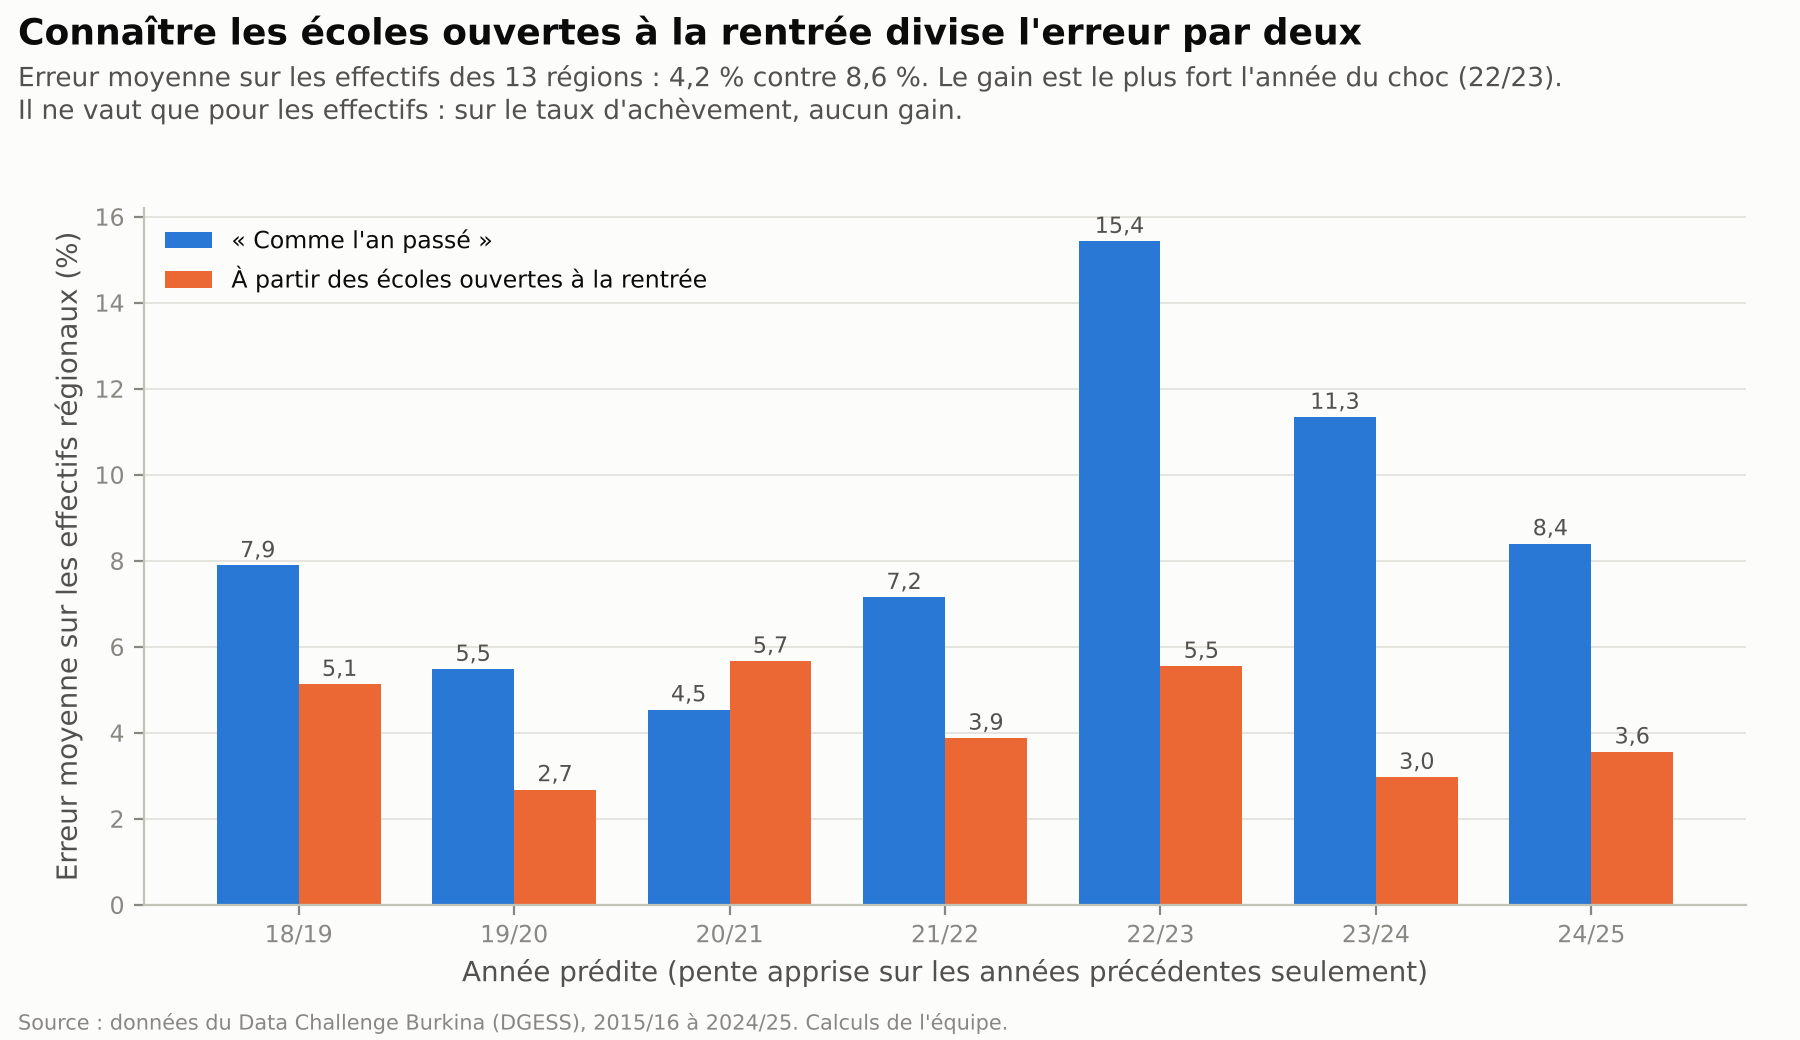

analyse/figures/14_projection_cohortes.png


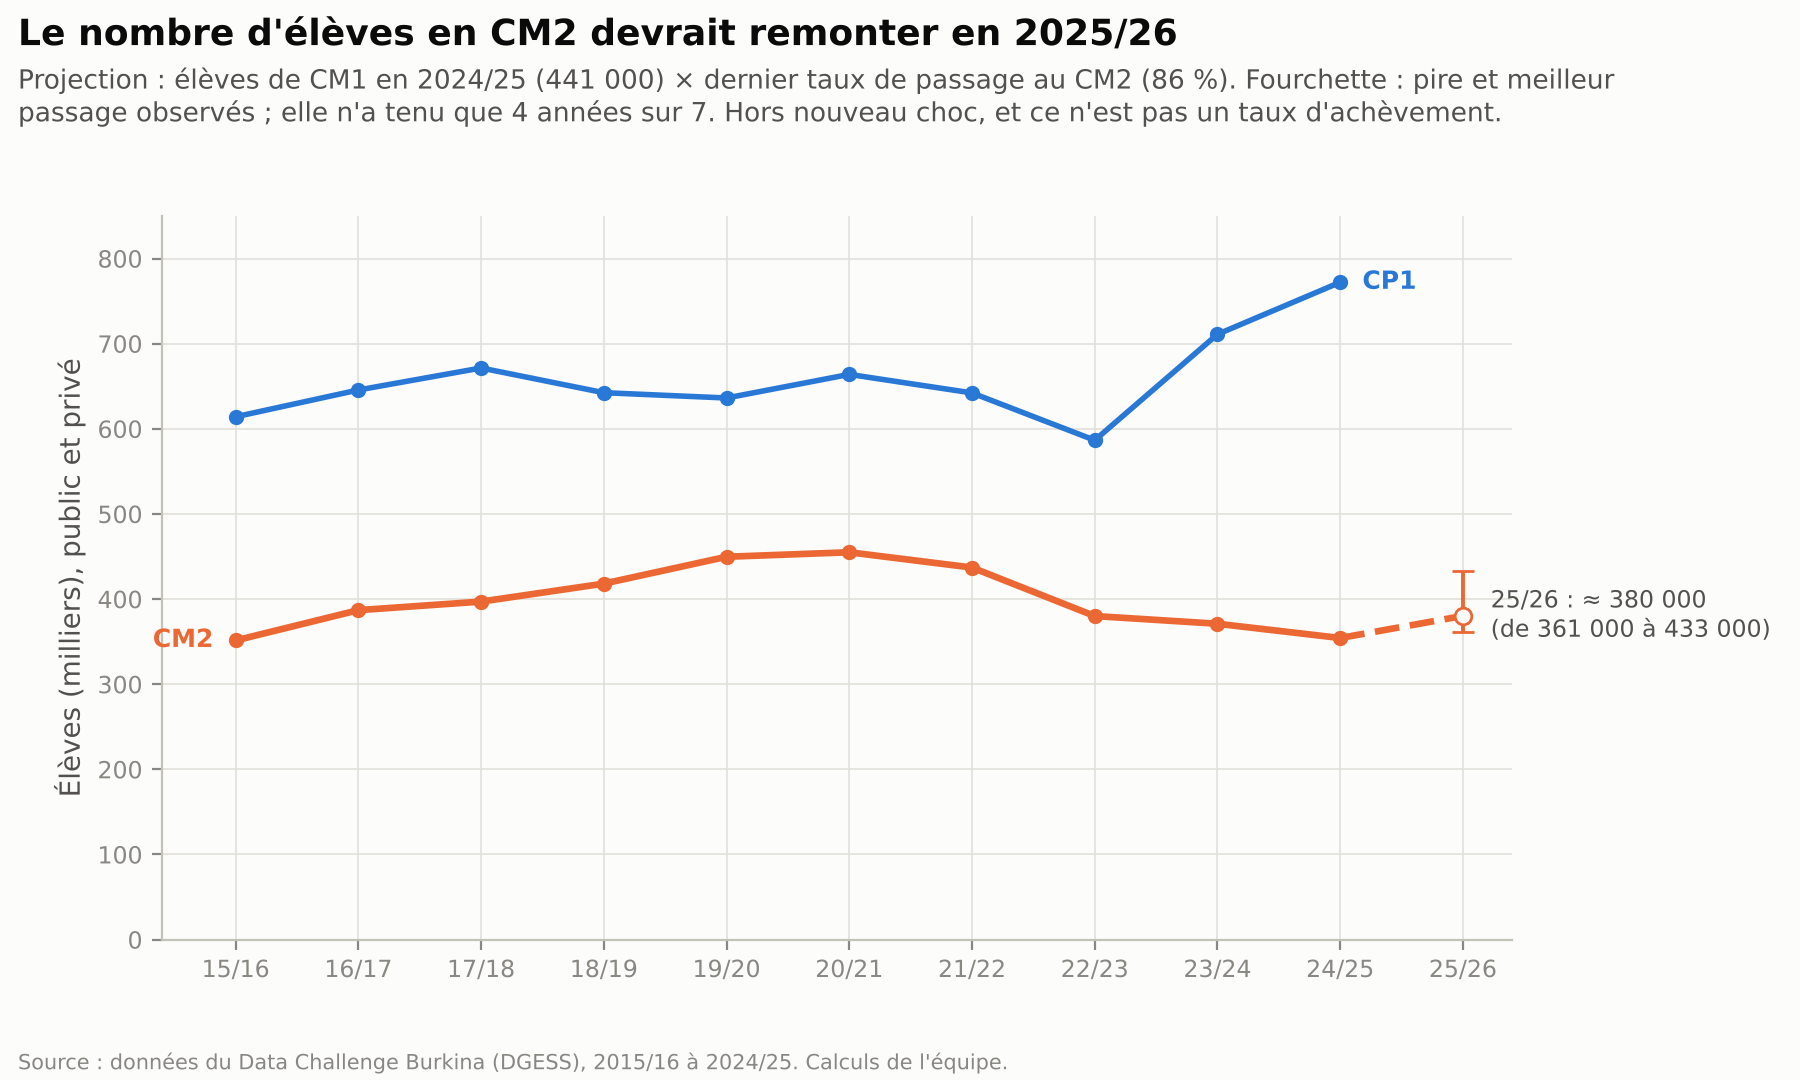

analyse/figures/15_matrice_priorite_2026_27.png


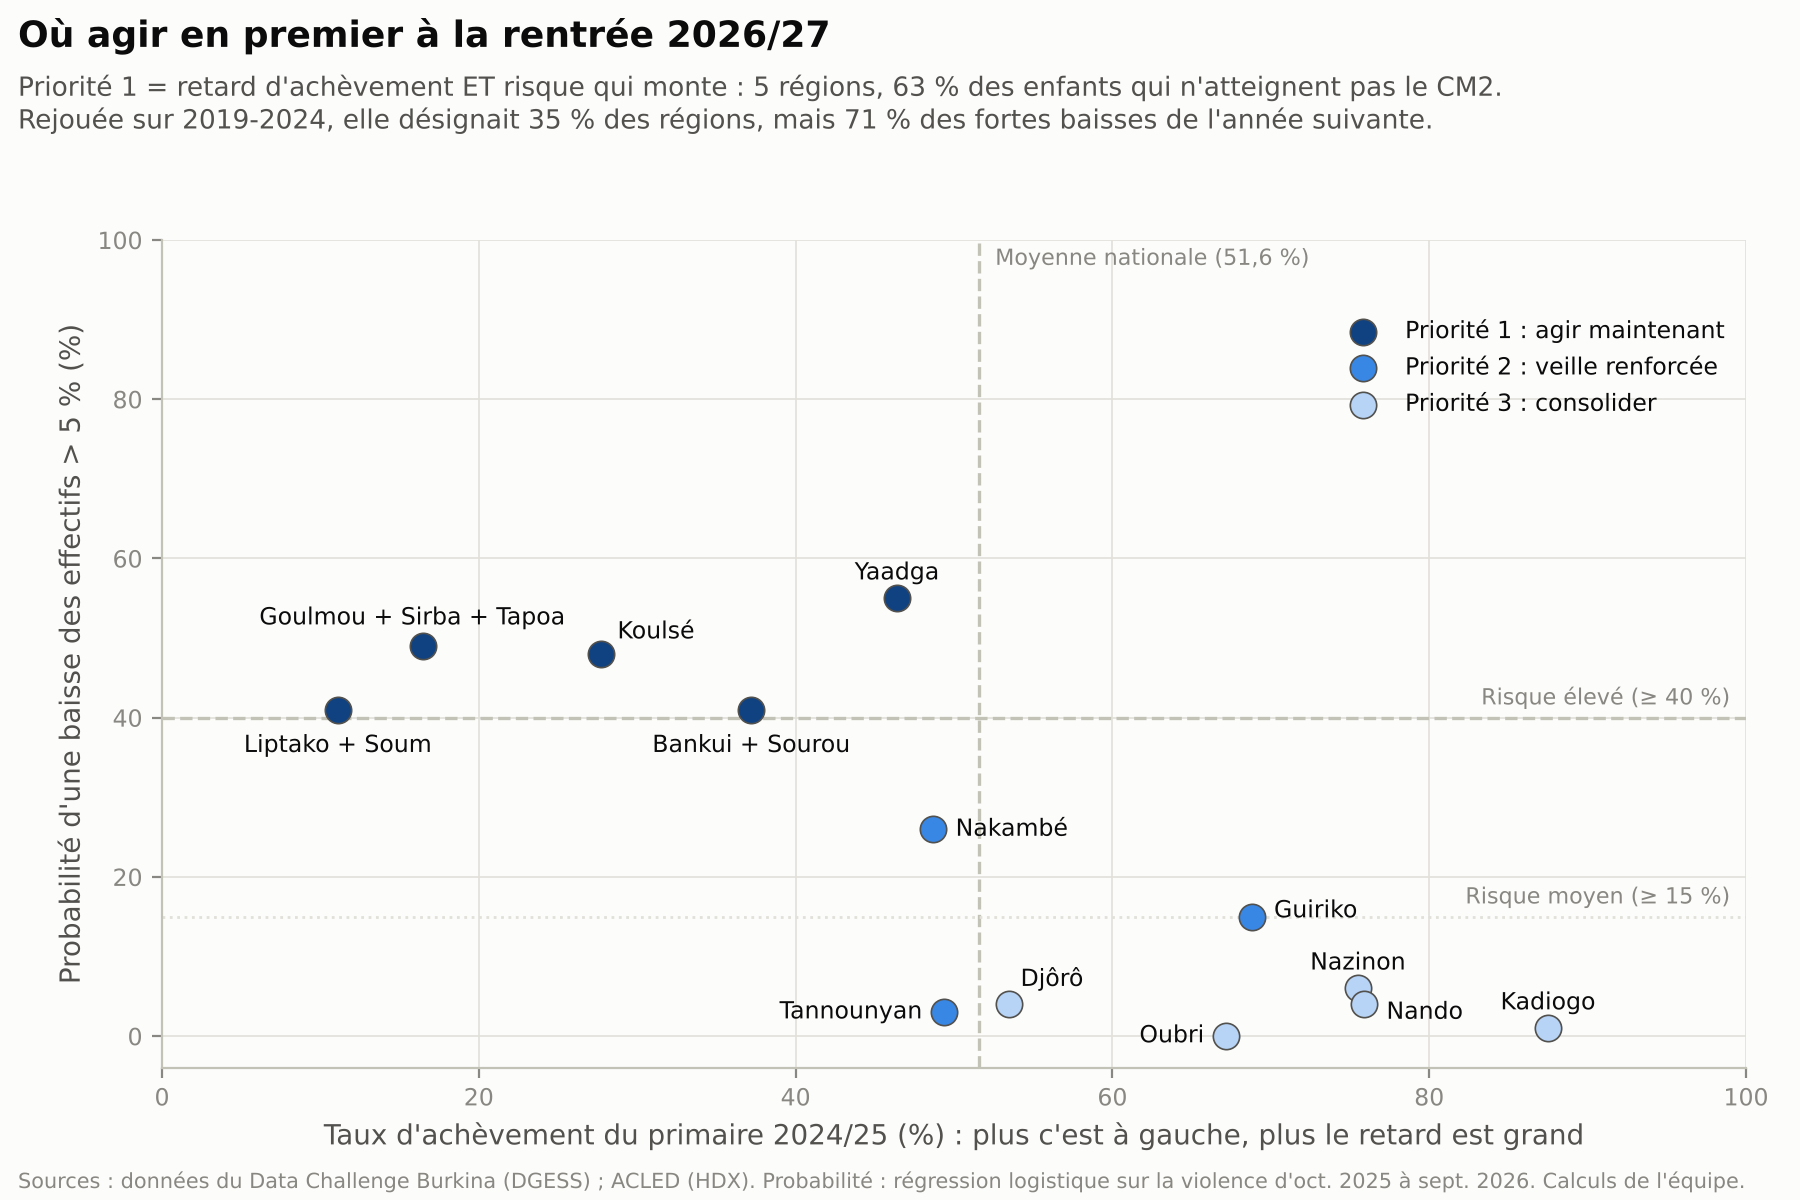

analyse/figures/16_profil_facteurs.png


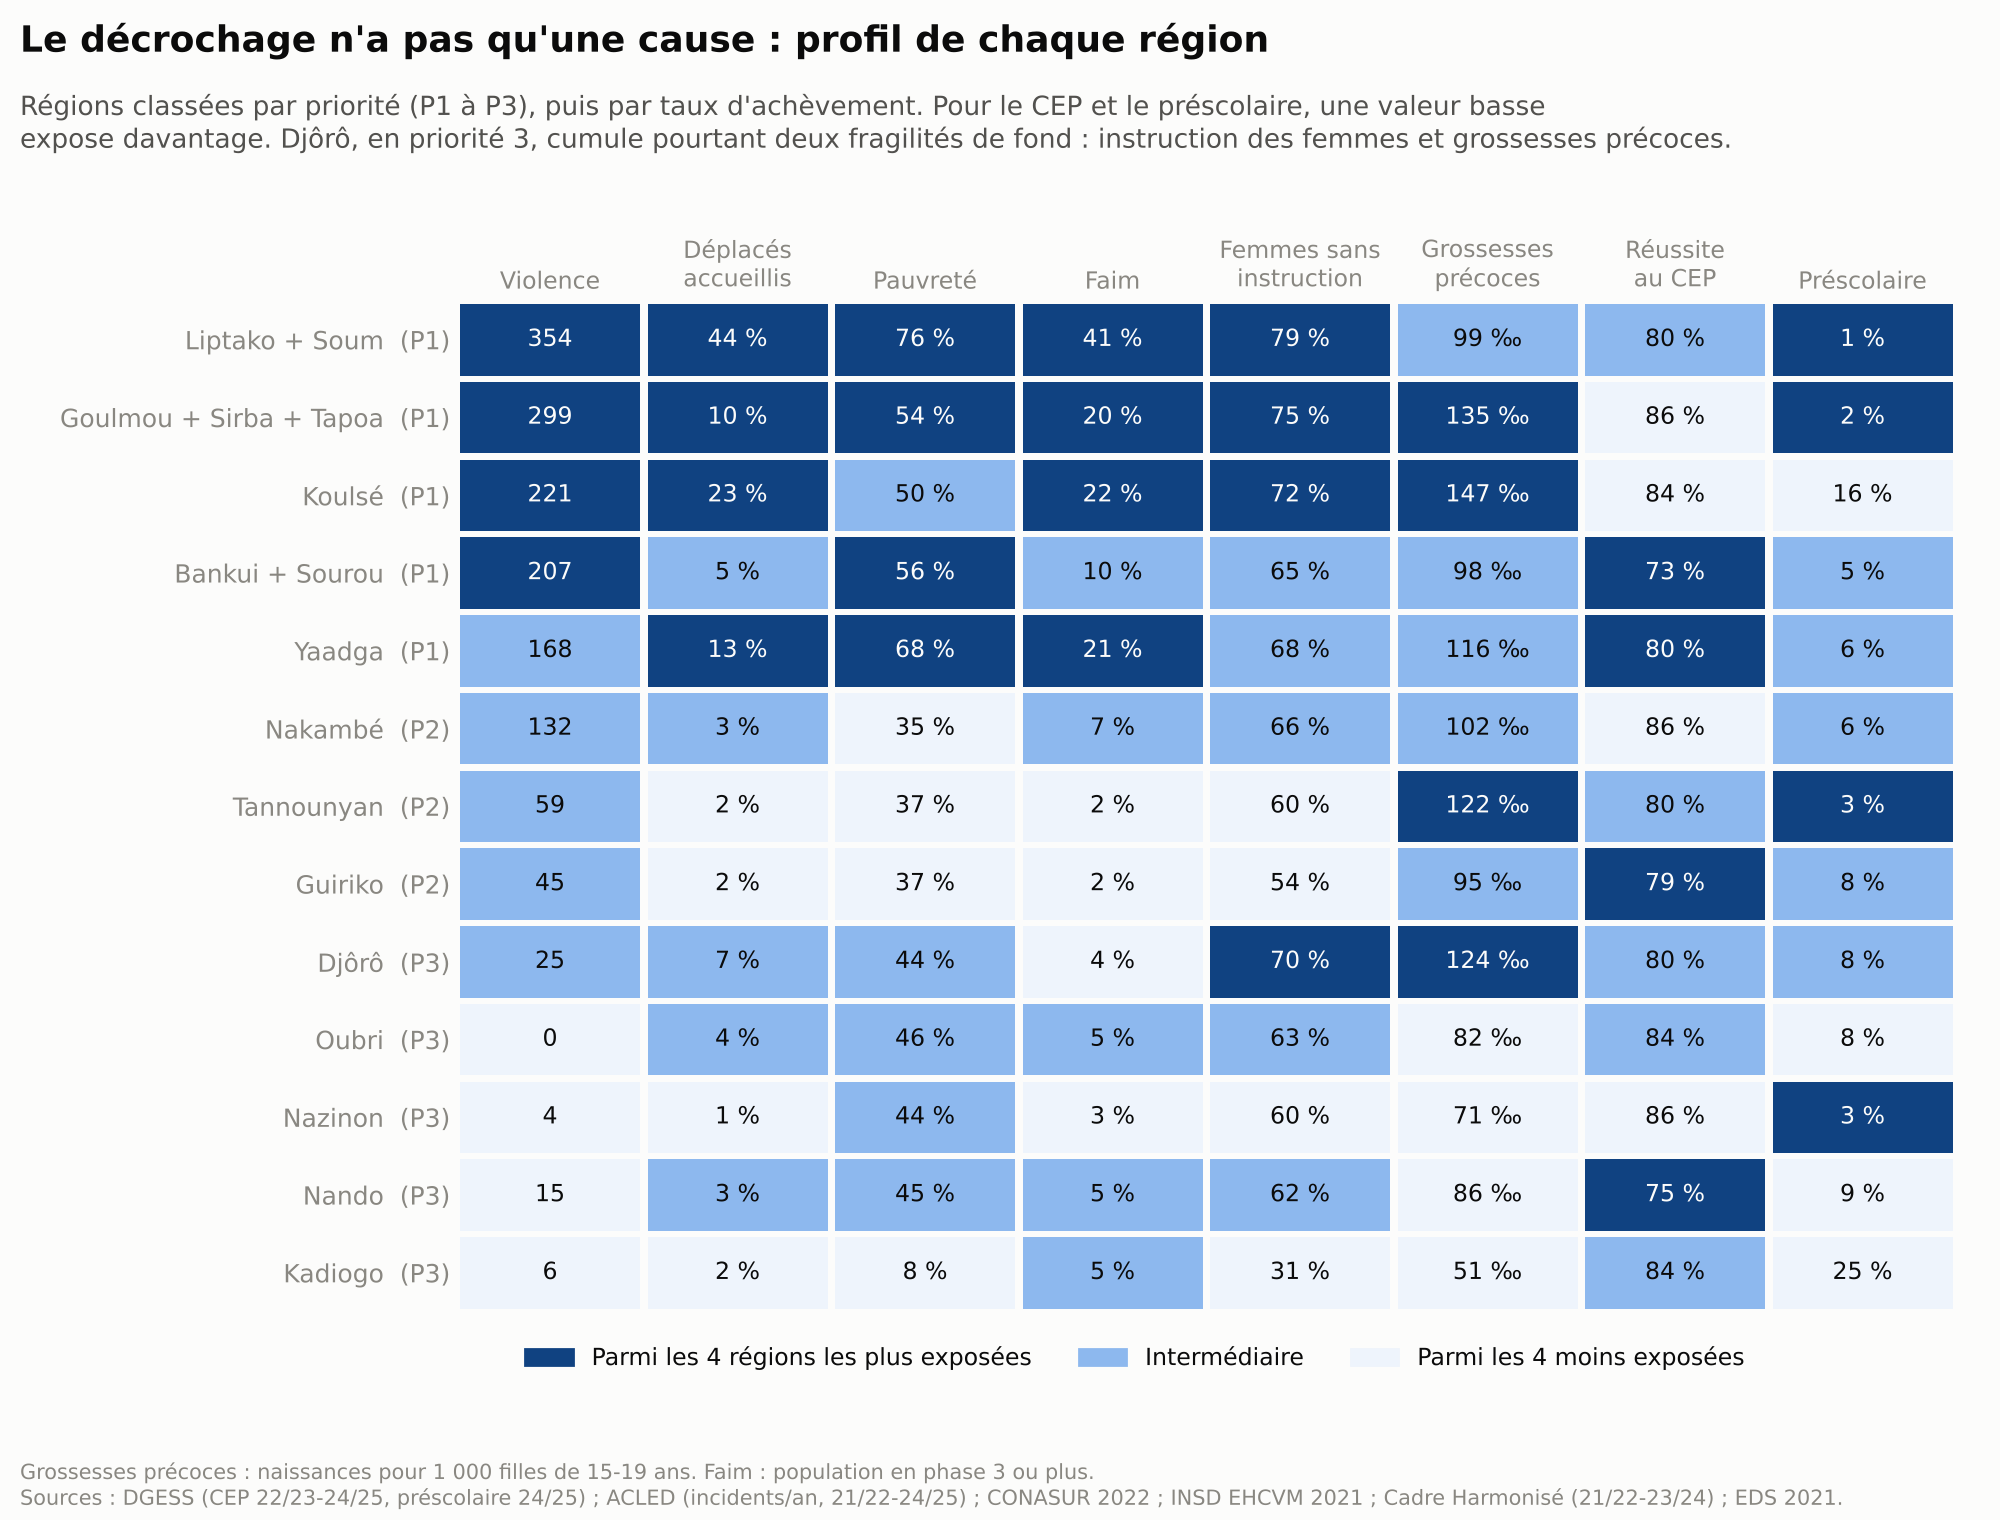

analyse/figures/17_calendrier_alerte.png


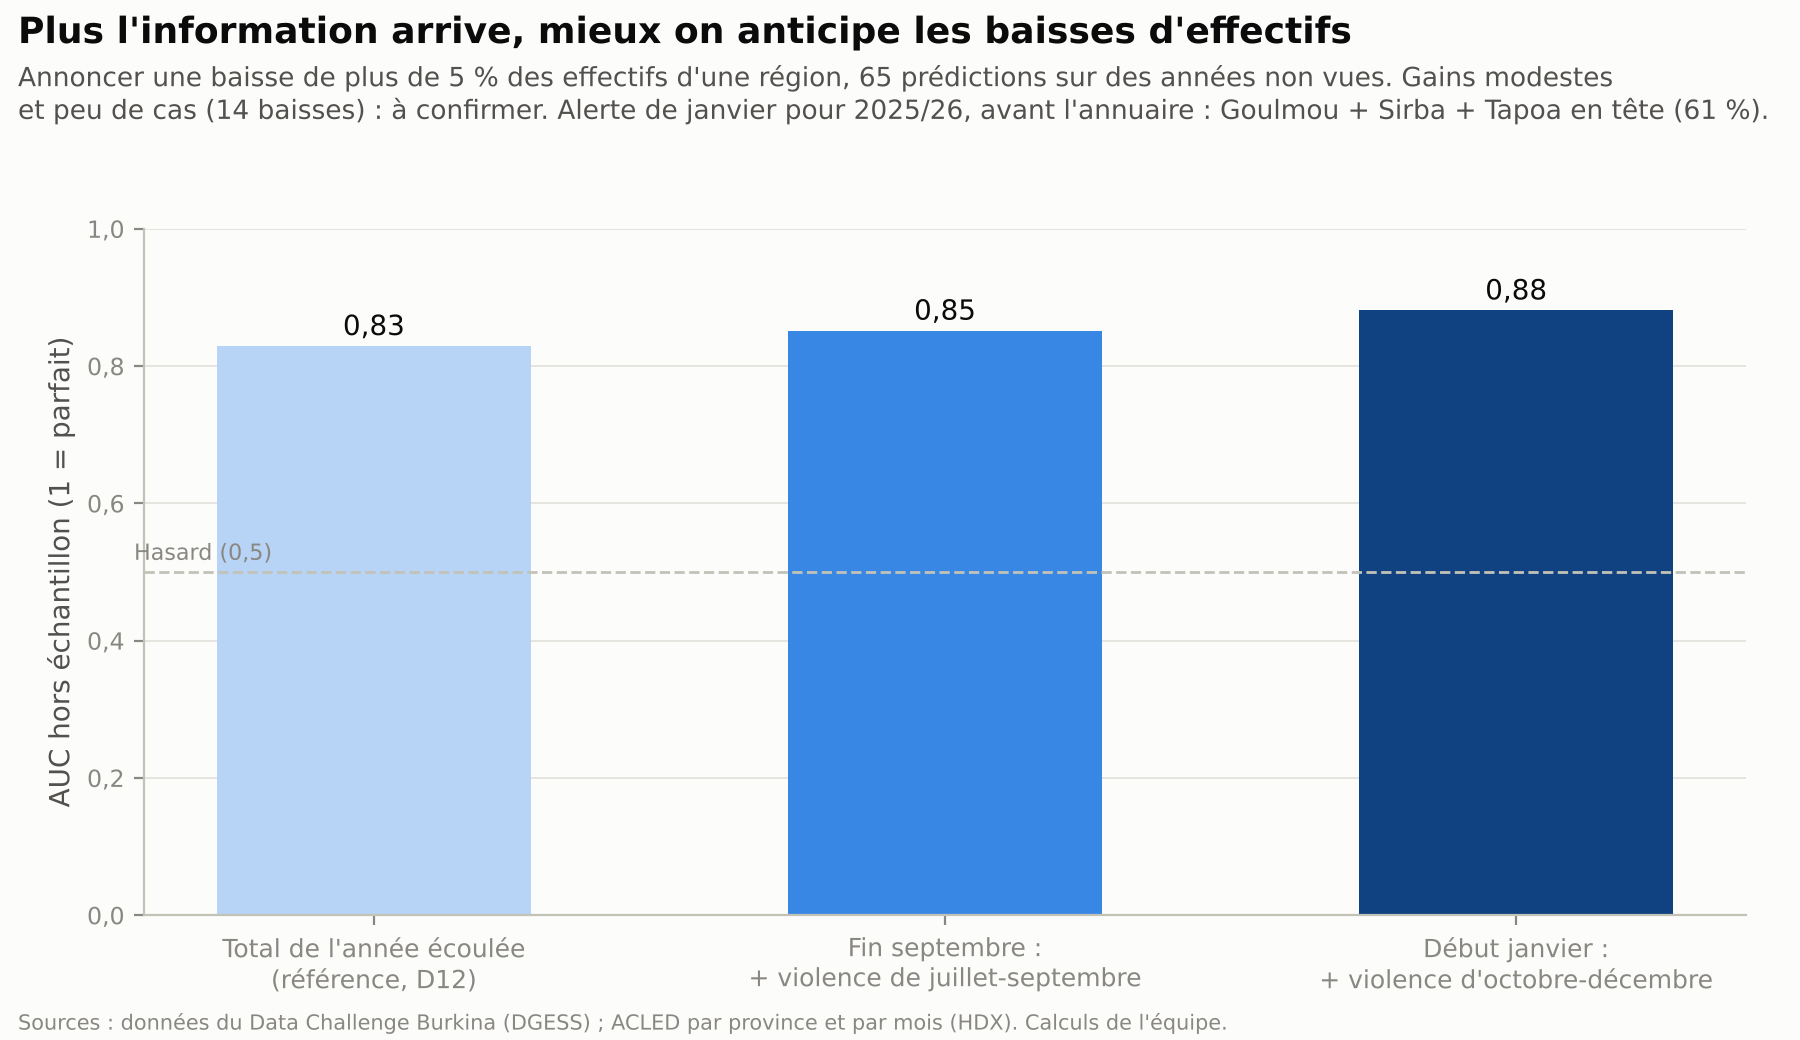

In [13]:
lancer_figures_approches = main
t0 = time.time()
sys.argv = ['figures_approches.py']
lancer_figures_approches()
montrer_figures(t0)

## 2. Données du tableau de bord

`scripts/export_tableau_de_bord.py`

In [14]:
import hashlib
import json
import math
import sys
from pathlib import Path
import geopandas as gpd
import numpy as np
import pandas as pd
sys.path.insert(0, "scripts")
import fiches_regionales as fiches
OUT = "dashboard/public/data/tableau_de_bord.json"
YEARS = fiches.YEARS
SHORT = fiches.SHORT
FACTORS = [
    ("violence", "Violence", "incidents par an", True, "Continuité éducative : écoles délocalisées, enseignement à distance, radio."),
    ("deplaces", "Déplacés accueillis", "% de la population", True, "Places d'accueil, classes passerelles, inscription sans pièces."),
    ("pauvrete", "Pauvreté", "% de la population", True, "Cantines scolaires, aides aux familles liées à la scolarité, fournitures."),
    ("faim", "Faim (phase 3 ou plus)", "% de la population", True, "Cantines scolaires pendant la soudure."),
    ("meres", "Femmes sans instruction", "% des 15-49 ans", True, "Alphabétisation des mères, associations de mères éducatrices."),
    ("grossesses", "Grossesses précoces", "naissances pour 1 000 filles de 15-19 ans", True, "Maintien des filles à l'école, lutte contre le mariage d'enfants."),
    ("cep", "Réussite au CEP", "%", False, None),
    ("prescolaire", "Préscolaire", "taux brut, %", False, "Préscolaire communautaire."),
]

In [15]:
def num(v, nd=1):
    return None if v is None or (isinstance(v, float) and math.isnan(v)) else round(float(v), nd)

In [16]:
def project(geom, lon0, lat_max, k):
    c = math.cos(math.radians(12.3))
    polys = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    parts = []
    for poly in polys:
        pts = [((x - lon0) * c * k, (lat_max - y) * k) for x, y in poly.exterior.coords]
        parts.append("M" + "L".join(f"{x:.1f},{y:.1f}" for x, y in pts) + "Z")
    return "".join(parts)

In [17]:
def carte():
    g = gpd.read_file("data/ref/regions_13.geojson")
    g["geometry"] = g.geometry.simplify(0.01, preserve_topology=True)
    lon0, lat0, lon1, lat1 = g.total_bounds
    k = 100
    out = {}
    for _, r in g.iterrows():
        p = r.geometry.representative_point()
        out[r.cle_presco] = {"d": project(r.geometry, lon0, lat1, k),
                             "lx": round((p.x - lon0) * math.cos(math.radians(12.3)) * k, 1),
                             "ly": round((lat1 - p.y) * k, 1)}
    w = (lon1 - lon0) * math.cos(math.radians(12.3)) * k
    return {"largeur": round(w, 1), "hauteur": round((lat1 - lat0) * k, 1), "regions": out}

In [18]:
def formule_risque():
    f = pd.read_csv("analyse/P17_formule_risque.csv")
    cles = {"Référence": "reference", "Alerte de septembre": "septembre", "Alerte de janvier": "janvier"}
    out = {"observations": int(f.observations.iloc[0]), "baisses": int(f.baisses.iloc[0])}
    for _, r in f.iterrows():
        k = next(v for c, v in cles.items() if r.modele.startswith(c))
        out[k] = {c: float(r[c]) for c in ["constante", "l_inc", "d_l_inc", "l_late", "l_rentree"] if c in r and pd.notna(r[c])}
    return out

In [19]:
def score_global():
    s = pd.read_csv("analyse/P18_score_global_2026_27.csv").set_index("region_2025").score_global
    names = {v: k for k, v in fiches.load()[0].drop_duplicates("cle").set_index("cle").region_2025.items()}
    rj = pd.read_csv("analyse/P18_score_global_rejoue.csv").set_index("mesure")
    return {"poids_risque": 0.5, "par_region": {names[n]: int(v) for n, v in s.items()},
            "rejoue": {"auc_score": round(float(rj.loc["Score global", "AUC_baisse_t+1"]), 2),
                       "auc_risque": round(float(rj.loc["Risque seul (violence)", "AUC_baisse_t+1"]), 2),
                       "baisses_score_pct": round(float(rj.loc["Score global", "baisses_prises_%"])),
                       "baisses_matrice_pct": round(float(rj.loc["Matrice (priorité 1)", "baisses_prises_%"])),
                       "perdus_score_pct": round(float(rj.loc["Score global", "eleves_perdus_pris_%"])),
                       "perdus_matrice_pct": round(float(rj.loc["Matrice (priorité 1)", "eleves_perdus_pris_%"]))},
            "trajectoire": trajectoire({names[n]: int(v) for n, v in s.items()})}

In [20]:
def trajectoire(final):
    t = pd.read_csv("analyse/P18_score_global_trajectoire.csv")
    annees = sorted(t.annee_cible.unique()) + ["26/27"]
    par = {}
    for cle, g in t.groupby("cle"):
        g = g.set_index("annee_cible").reindex(annees[:-1])
        par[cle] = {"score": [int(v) for v in g.score] + [final[cle]],
                    "chute": [None if pd.isna(v) else int(v) for v in g.chute_observee] + [None]}
    return {"annees": annees, "par_region": par}

In [21]:
def facteur_dominant():
    f = pd.read_csv("analyse/P19_facteur_dominant.csv").set_index("region_2025")
    names = {v: k for k, v in fiches.load()[0].drop_duplicates("cle").set_index("cle").region_2025.items()}
    ids = [c for c in f.columns if c not in ("dominant", "second")]
    txt = lambda v: None if pd.isna(v) else str(v)
    return {"par_region": {names[n]: {"dominant": txt(r.dominant), "second": txt(r.second),
                                      "contributions": {i: float(r[i]) for i in ids}} for n, r in f.iterrows()}}

In [22]:
def main():
    data = fiches.load()
    p = data[0]
    nat = p[p.region == "NATIONAL"].set_index("annee").loc[YEARS]
    keys = sorted(p[p.region != "NATIONAL"].cle.unique())
    names = p.drop_duplicates("cle").set_index("cle").region_2025
    prio = pd.read_csv("analyse/P13_matrice_priorite_2026_27.csv").set_index("region_2025")
    prof = pd.read_csv("analyse/P14_profil_facteurs.csv").set_index("region_2025")
    cal = pd.read_csv("analyse/P16_alertes_calendrier.csv").set_index("region")
    cal.columns = ["janv_2025_26", "sept_2026_27", "ref_2026_27"]
    acled = pd.read_csv("analyse/acled_region_annee.csv")
    sy = [f"{y}-{y + 1}" for y in range(2015, 2026)]
    nowc = pd.read_csv("analyse/P12_nowcast_ecoles.csv").set_index("annee").loc["moyenne"]
    d = p[p.region != "NATIONAL"].dropna(subset=["dlog_eleves", "dlog_ecoles"])
    slope, const = np.polyfit(d.dlog_ecoles, d.dlog_eleves, 1)
    tap_nat = float(nat.TAP_T.iloc[-1])

    regions = []
    for cle in keys:
        c = fiches.contenu(cle, data)
        r, f, name = c["r"], c["f"], c["name25"]
        pr, pf, ca = prio.loc[name], prof.loc[name], cal.loc[name]
        inc = acled[acled.cle == cle].set_index("annee").incidents.reindex(sy)
        facteurs = {fid: {"valeur": num(pf["incidents_moy"] if fid == "violence" else pf[fid]),
                          "niveau": int(pf[f"{fid}_niveau"])} for fid, *_ in FACTORS}
        lev_f = [lev for fid, _, _, _, lev in FACTORS if lev and facteurs[fid]["niveau"] == 1]
        regions.append({
            "cle": cle, "nom": name, "ancienne": c["old"], "codes": r.codes_2025.iloc[0], "type": r.type_2025.iloc[0],
            "profil": c["profile"], "priorite": int(pr.priorite),
            "tap": [num(v) for v in r.TAP_T], "tap_f": [num(v) for v in r.TAP_F], "tap_g": [num(v) for v in r.TAP_G],
            "eleves": [int(v) for v in r.eleves_T], "ecoles": [int(v) for v in r.ecoles],
            "incidents": [None if np.isnan(v) else int(v) for v in inc],
            "prevision_2025_26": {"centrale": num(f.prevision_25_26), "basse": num(f.fourchette_basse),
                                  "haute": num(f.fourchette_haute)},
            "enfants_hors_cm2": int(f.enfants_hors_CM2_estimes),
            "probabilites": {"janv_2025_26": int(ca.janv_2025_26), "sept_2026_27": int(ca.sept_2026_27),
                             "ref_2026_27": int(ca.ref_2026_27)},
            "facteurs": facteurs, "faits": c["facts"], "leviers": c["levers"], "leviers_facteurs": lev_f,
        })
    payload = {
        "annees": SHORT, "annees_violence": [y[2:4] + "/" + y[7:] for y in sy],
        "national": {"tap": [num(v) for v in nat.TAP_T], "eleves": [int(v) for v in nat.eleves_T]},
        "seuils": {"tap_national": round(tap_nat, 1), "risque_eleve": 40, "risque_moyen": 15},
        "nowcast": {"pente": round(float(slope), 4), "constante": round(float(const), 4),
                    "erreur_pct": round(float(nowc["effectifs_ecoles_%"]), 1),
                    "erreur_persistance_pct": round(float(nowc["effectifs_persistance_%"]), 1)},
        "validation": {"rang_tap": 0.97, "auc_reference": 0.83, "auc_septembre": 0.85, "auc_janvier": 0.88,
                       "matrice_regions_pct": 35, "matrice_baisses_pct": 71, "matrice_perdus_pct": 69},
        "facteurs_def": [{"id": fid, "libelle": lab, "unite": u, "haut_expose": up, "levier": lev} for fid, lab, u, up, lev in FACTORS],
        "facteur_dominant": facteur_dominant(),
        "formule_risque": formule_risque(),
        "score_global": score_global(),
        "carte": carte(),
        "regions": regions,
    }
    body = json.dumps(payload, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    payload["version"] = hashlib.sha256(body.encode()).hexdigest()[:12]
    payload["genere_le"] = pd.Timestamp.today().strftime("%Y-%m-%d")
    with open(OUT, "w") as fh:
        json.dump(payload, fh, ensure_ascii=False, separators=(",", ":"))
    print(f"{len(regions)} régions, version {payload['version']}, {len(json.dumps(payload)) / 1e3:.0f} ko -> {OUT}")

In [23]:
lancer_export_tableau_de_bord = main
t0 = time.time()
sys.argv = ['export_tableau_de_bord.py']
lancer_export_tableau_de_bord()
montrer_figures(t0)

13 régions, version 1f8ba48c18b2, 57 ko -> dashboard/public/data/tableau_de_bord.json


## 3. Fiches régionales

`scripts/fiches_regionales.py`

In [24]:
import os
import sys
import unicodedata
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = [y[2:4] + "/" + y[7:] for y in YEARS]
BLUE, BAND, NAT = "#2a78d6", "#b7d3f6", "#c3c2b7"
INK, INK2, MUTED, GRID, SURFACE, TILE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb", "#f0efec"
RISK = {"élevé": ("#d03b3b", "⚠"), "moyen": ("#fab219", "!"), "faible": ("#0ca30c", "✓")}
LEVERS = {
    "Effondrement": [
        "Rouvrir de façon sécurisée et ouvrir des espaces temporaires d'apprentissage (chantier 2 du ministère).",
        "Réinscrire les élèves déplacés là où ils vivent maintenant.",
    ],
    "Choc puis reprise partielle": [
        "Accompagner le retour : suivre les élèves revenus dans les écoles rouvertes, organiser le rattrapage.",
        "Offrir une passerelle aux enfants sortis de l'école (centres SSA/P, chantier 9).",
    ],
    "Érosion": [
        "Chercher les causes hors insécurité : visites dans les écoles où les effectifs du CM1-CM2 baissent.",
        "Suivre chaque année les sorties en cours de cycle, avant qu'elles ne deviennent des abandons.",
    ],
    "Stabilité / accueil": [
        "Garder des places pour les élèves déplacés accueillis (classes, enseignants).",
        "Maintenir le suivi annuel : la région n'est pas à l'abri d'un recul.",
    ],
}

In [25]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [26]:
def fr(v, nd=0, sign=False):
    s = f"{v:+,.{nd}f}" if sign else f"{v:,.{nd}f}"
    return s.replace(",", " ").replace(".", ",")

In [27]:
def pts(v):
    return f"{fr(v, 1, True)} point" + ("s" if abs(v) >= 2 else "")

In [28]:
def load():
    p = pd.read_csv("analyse/panel_region_annee_2025.csv")
    p["cle"] = p.region.map(key)
    fc = pd.read_csv("analyse/P9_prevision_2025_26_alerte.csv")
    fc["cle"] = fc.cle.astype(str)
    ex = pd.read_csv("analyse/P1_sorties_excedentaires.csv")
    ex["cle"] = ex.iloc[:, 0].map(key)
    typo = pd.read_csv("analyse/P2_typologie_regions.csv")
    typo["cle"] = typo.region.map(key)
    prob = pd.read_csv("analyse/P11_probabilites_alerte.csv")
    acled = pd.read_csv("analyse/acled_region_annee.csv")
    pov = pd.read_csv("data/externe_propre/pauvrete_ehcvm_2021_regions.csv")
    pov["cle"] = pov.region.map(key)
    return p, fc, ex, typo, prob, acled, pov

In [29]:
def risk_level(pct):
    return "élevé" if pct >= 40 else ("moyen" if pct >= 15 else "faible")

In [30]:
def tile(fig, x, y, w, h, value, label, sub):
    fig.patches.append(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.008",
                                      transform=fig.transFigure, facecolor=TILE, edgecolor="none"))
    fig.text(x + 0.012, y + h - 0.016, label, fontsize=7.6, color=INK2, va="top")
    fig.text(x + 0.012, y + h * 0.42, value, fontsize=16, color=INK, va="center", fontweight="bold")
    fig.text(x + 0.012, y + 0.010, sub, fontsize=7, color=INK2, va="bottom")

In [31]:
def contenu(cle, data):
    p, fc, ex, typo, prob, acled, pov = data
    r = p[p.cle == cle].set_index("annee").loc[YEARS]
    n = p[p.region == "NATIONAL"].set_index("annee").loc[YEARS]
    name25, old = r.region_2025.iloc[0], r.region.iloc[0].title().replace("Du", "du")
    f = fc[fc.cle == cle].iloc[0]
    e = ex[ex.cle == cle].iloc[0]
    t = typo[typo.cle == cle].iloc[0]
    profile = {1: "Choc puis reprise partielle", 2: "Effondrement", 3: "Érosion", 4: "Stabilité / accueil"}[int(t.groupe_k4)]
    pr26 = float(prob.set_index("region_2025").loc[name25, "rentrée 2026/27"])
    level = risk_level(pr26)
    inc = acled[acled.cle == cle].set_index("annee").incidents
    poverty = float(pov.set_index("cle").loc[cle, "incidence_pauvrete_2021_pct"])

    tap0, tap1, tap21 = r.TAP_T.iloc[0], r.TAP_T.iloc[-1], r.TAP_T.loc["2021-2022"]
    el_max, el_now = r.eleves_T.max(), r.eleves_T.iloc[-1]
    ec_worst = (r.ecoles / r.ecoles.cummax() - 1).min() * 100
    g, fgl = r.TAP_G.iloc[-1], r.TAP_F.iloc[-1]
    inc24, inc25 = inc.get("2024-2025", np.nan), inc.get("2025-2026", np.nan)

    facts = [f"Le taux d'achèvement est passé de {fr(tap0, 1)} % en 2015/16 à {fr(tap1, 1)} % en 2024/25 "
             f"({pts(tap1 - tap0)}), contre {fr(n.TAP_T.iloc[-1], 1)} % au niveau national."]
    if ec_worst <= -30:
        facts.append(f"Jusqu'à {fr(-ec_worst)} % des écoles ont été perdues au pire moment de la crise.")
    elif tap1 - tap21 <= -8:
        closed = ("sans fermeture d'écoles" if -ec_worst < 1 else
                  f"sans fermeture massive d'écoles (au plus {fr(-ec_worst)} % fermées en même temps)")
        facts.append(f"Le recul ({pts(tap1 - tap21)} depuis 2021/22) s'est produit {closed} : "
                     "l'insécurité n'explique pas tout.")
    if not np.isnan(inc25) and max(inc24, inc25) < 30:
        facts.append(f"Les incidents sécuritaires restent rares : {fr(inc24)} entre oct. 2024 et sept. 2025, "
                     f"{fr(inc25)} entre oct. 2025 et sept. 2026.")
    elif not np.isnan(inc25) and inc24 > 0:
        trend = "ont presque doublé" if inc25 >= 1.8 * inc24 else ("ont augmenté" if inc25 > 1.10 * inc24 else
                                                                  ("ont baissé" if inc25 < 0.90 * inc24 else "sont stables"))
        facts.append(f"Les incidents sécuritaires {trend} : {fr(inc24)} entre oct. 2024 et sept. 2025, "
                     f"{fr(inc25)} entre oct. 2025 et sept. 2026.")
    gap = fgl - g
    who = "les garçons achèvent moins que les filles" if gap > 1 else (
        "les filles achèvent moins que les garçons" if gap < -1 else "garçons et filles achèvent autant")
    facts.append(f"En 2024/25, {who} ({fr(g, 1)} % contre {fr(fgl, 1)} %).")
    levers = list(LEVERS[profile])
    if profile == "Stabilité / accueil":
        levers = []
        if e.cumul_17_18_a_23_24 < 0:
            levers.append("Région d'accueil : garder des places pour les élèves déplacés (classes, enseignants).")
        if tap1 < 60:
            levers.append(f"Achèvement stable mais modeste ({fr(tap1, 1)} %) : leviers structurels (cantines endogènes, "
                          "chantier 5 ; suivi des élèves en retard d'âge).")
        if tap1 - tap21 <= -8:
            levers.append(f"Comprendre le recul récent ({pts(tap1 - tap21)} depuis 2021/22) : visites dans les écoles "
                          "où les effectifs du CM1-CM2 baissent.")
        levers.append("Maintenir le suivi annuel : la région n'est pas à l'abri d'un recul.")
    if level == "élevé":
        levers.append("Risque élevé pour 2026/27 : préparer dès maintenant un plan de continuité (lieux de repli, "
                      "enseignants mobiles, liste des élèves à suivre).")
    return {k: v for k, v in locals().items() if k in ('r', 'n', 'name25', 'old', 'f', 'e', 't', 'profile', 'pr26', 'level', 'inc', 'poverty', 'tap0', 'tap1', 'tap21', 'el_max', 'el_now', 'ec_worst', 'g', 'fgl', 'inc24', 'inc25', 'facts', 'levers')}

In [32]:
C1, C2, C3 = "#104281", "#3987e5", "#86b6ef"
FG, FG2, FG3, LINE, EDGE, CARD, BAD, NATC = "#0f172a", "#475569", "#7d8799", "#e3e7ed", "#cfd5de", "#f4f6f9", "#b42318", "#b9c2cf"
Z2, Z3 = "#dfe4eb", "#c3cbd7"
PRIO = {1: ("Priorité 1", "agir maintenant"), 2: ("Priorité 2", "veille renforcée"), 3: ("Priorité 3", "consolider")}
NOM_ACTION = {"violence": "l'insécurité", "deplaces": "l'accueil des déplacés", "pauvrete": "la pauvreté", "faim": "la faim",
              "meres": "l'instruction des mères", "grossesses": "les grossesses précoces", "prescolaire": "le préscolaire"}

In [33]:
def _style():
    plt.rcParams.update({"font.family": ["Inter"], "font.size": 9, "axes.edgecolor": EDGE,
                         "axes.labelcolor": FG2, "xtick.color": FG3, "ytick.color": FG3, "pdf.fonttype": 42})

In [34]:
def _carte(fig, x, y, w, h):
    fig.patches.append(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.012",
                                      transform=fig.transFigure, facecolor=CARD, edgecolor="none", zorder=-5))

In [35]:
def _axes_propres(ax):
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(LINE)
    ax.tick_params(length=0, labelsize=7.5)
    ax.set_facecolor("none")

In [36]:
def classe(v):
    return C1 if v >= 50 else (C2 if v >= 25 else C3)

In [37]:
def make(cle, jeu, out):
    _style()
    import textwrap
    R = {r["cle"]: r for r in jeu["regions"]}
    r, sg, fdj = R[cle], jeu["score_global"], jeu["facteur_dominant"]["par_region"][cle]
    defs = {d["id"]: d for d in jeu["facteurs_def"]}
    dom = fdj["dominant"]
    s = sg["par_region"][cle]
    p = r["probabilites"]["ref_2026_27"]
    tap = r["tap"][-1]
    rang = 1 + sum(1 for k, v in sg["par_region"].items() if v > s)
    brutal, lent = 50 * p / 100, 50 * (1 - tap / 100)
    niveau = "élevé" if s >= 50 else ("moyen" if s >= 25 else "faible")

    fig = plt.figure(figsize=(8.27, 11.69))
    fig.patch.set_facecolor("white")
    L, W = 0.06, 0.88

    fig.text(L, 0.968, "FICHE RÉGIONALE · RISQUE DE DÉCROCHAGE AU PRIMAIRE · RENTRÉE 2026/27", fontsize=7.5, color=FG3, va="top", fontweight="bold")
    fig.text(L, 0.950, r["nom"], fontsize=25, fontweight="bold", color=FG, va="top")
    lib, sous = PRIO[r["priorite"]]
    fig.patches.append(FancyBboxPatch((L, 0.9035), 0.012, 0.0085, boxstyle="round,pad=0,rounding_size=0.002",
                                      transform=fig.transFigure, facecolor=[C1, C2, C3][r["priorite"] - 1], edgecolor="none"))
    fig.text(L + 0.018, 0.912, f"{lib} · {sous} · ancienne région {r['ancienne']}", fontsize=9.5, color=FG2, va="top")

    y0, h0 = 0.745, 0.145
    _carte(fig, L, y0, W, h0)
    fig.text(L + 0.025, y0 + h0 - 0.02, "Score global de risque", fontsize=10.5, fontweight="bold", color=FG, va="top")
    fig.text(L + W - 0.025, y0 + h0 - 0.02, f"{rang}{'re' if rang == 1 else 'e'} sur 13 · {niveau}", fontsize=8.5, color=FG3, va="top", ha="right")
    fig.text(L + 0.025, y0 + 0.058, f"{s}", fontsize=40, fontweight="bold", color=classe(s), va="baseline")
    fig.text(L + 0.025 + 0.041 * len(str(s)) + 0.012, y0 + 0.058, "/ 100", fontsize=13, color=FG3, va="baseline")
    bx, bw, by = L + 0.30, W - 0.325, y0 + 0.075
    fig.patches.append(FancyBboxPatch((bx, by), bw, 0.016, boxstyle="round,pad=0,rounding_size=0.004", transform=fig.transFigure, facecolor="white", edgecolor="none"))
    fig.patches.append(FancyBboxPatch((bx, by), bw * brutal / 100, 0.016, boxstyle="round,pad=0,rounding_size=0.004", transform=fig.transFigure, facecolor=FG, edgecolor="none"))
    fig.patches.append(FancyBboxPatch((bx + bw * brutal / 100, by), bw * lent / 100, 0.016, boxstyle="round,pad=0,rounding_size=0.004", transform=fig.transFigure, facecolor=Z3, edgecolor="none"))
    for yq, col in [(by - 0.0195, FG), (by - 0.0365, Z3)]:
        fig.patches.append(FancyBboxPatch((bx, yq), 0.009, 0.0065, boxstyle="round,pad=0,rounding_size=0.0015",
                                          transform=fig.transFigure, facecolor=col, edgecolor="none"))
    fig.text(bx + 0.016, by - 0.012, f"Chute des effectifs (violence) : {fr(brutal)}", fontsize=8.2, color=FG, va="top")
    fig.text(bx + 0.016, by - 0.029, f"Enfants qui n'achèvent pas le primaire : {fr(lent)}", fontsize=8.2, color="#8a94a5", va="top")
    fig.text(L + 0.025, y0 + 0.018, f"Moitié risque de chute des effectifs ({fr(p)} %), moitié part d'enfants qui n'achèvent pas ({fr(100 - tap, 1)} %).",
             fontsize=7.8, color=FG3)

    y1, h1 = 0.585, 0.145
    _carte(fig, L, y1, W, h1)
    fig.text(L + 0.025, y1 + h1 - 0.02, "Sur quoi agir", fontsize=10.5, fontweight="bold", color=FG, va="top")
    if dom:
        fig.text(L + W - 0.025, y1 + h1 - 0.02, "poids de chaque facteur", fontsize=8.5, color=FG3, va="top", ha="right")
    if dom:
        fig.text(L + 0.025, y1 + h1 - 0.047, f"Agir sur {NOM_ACTION[dom]}", fontsize=14, fontweight="bold", color=FG, va="top")
        lev = textwrap.wrap(defs[dom]["levier"], 52)
        for i, ln in enumerate(lev[:3]):
            fig.text(L + 0.025, y1 + h1 - 0.075 - i * 0.016, ln, fontsize=9, color=FG2, va="top")
        if fdj["second"]:
            fig.text(L + 0.025, y1 + 0.018, f"Ensuite : {NOM_ACTION[fdj['second']]}", fontsize=8.5, color=FG3)
    else:
        fig.text(L + 0.025, y1 + h1 - 0.047, "Aucun facteur au-dessus de la moyenne", fontsize=13, fontweight="bold", color=FG, va="top")
        fig.text(L + 0.025, y1 + h1 - 0.075, "Consolider ce qui marche.", fontsize=9, color=FG2, va="top")
    top = sorted(fdj["contributions"].items(), key=lambda kv: -kv[1])[:4] if dom else []
    mx = max(abs(v) for _, v in fdj["contributions"].items()) or 1
    for i, (fid, v) in enumerate(top):
        yy = y1 + h1 - 0.052 - i * 0.022
        fig.text(L + 0.49, yy, defs[fid]["libelle"], fontsize=8.2, color=FG2, va="center")
        fig.patches.append(FancyBboxPatch((L + 0.68, yy - 0.004), 0.15, 0.008, boxstyle="round,pad=0,rounding_size=0.003", transform=fig.transFigure, facecolor="white", edgecolor="none"))
        if v > 0:
            fig.patches.append(FancyBboxPatch((L + 0.68, yy - 0.004), 0.15 * v / mx, 0.008, boxstyle="round,pad=0,rounding_size=0.003",
                                              transform=fig.transFigure, facecolor=FG if fid == dom else C3, edgecolor="none"))

    tr = sg["trajectoire"]
    ann, sc, ch = tr["annees"], tr["par_region"][cle]["score"], tr["par_region"][cle]["chute"]
    y2, h2 = 0.375, 0.19
    _carte(fig, L, y2, W, h2)
    fig.text(L + 0.025, y2 + h2 - 0.02, "Le score, année par année", fontsize=10.5, fontweight="bold", color=FG, va="top")
    fig.text(L + W - 0.025, y2 + h2 - 0.02, f"{ann[-1]} prévu : {sc[-1]}", fontsize=9, color=C1, va="top", ha="right", fontweight="bold")
    ax = fig.add_axes([L + 0.04, y2 + 0.062, W - 0.10, h2 - 0.105])
    n = len(ann)
    ax.axhspan(50, 100, color=Z3, alpha=.45, lw=0)
    ax.axhspan(25, 50, color=Z2, alpha=.45, lw=0)
    ax.plot(range(n - 1), sc[:-1], color=FG, lw=2, solid_capstyle="round", zorder=3)
    ax.plot([n - 2, n - 1], sc[-2:], color=FG, lw=2, ls=(0, (3, 3)), zorder=3)
    for i in range(n - 1):
        if ch[i] == 1:
            ax.scatter(i, sc[i], s=70, facecolor="white", edgecolor=BAD, linewidth=2, zorder=4)
        else:
            ax.scatter(i, sc[i], s=14, color=FG, zorder=4)
    ax.scatter(n - 1, sc[-1], s=200, color=C1, alpha=.18, lw=0, zorder=3)
    ax.scatter(n - 1, sc[-1], s=60, facecolor="white", edgecolor=C1, linewidth=2.2, zorder=5)
    ax.annotate(f"{sc[-1]}", (n - 1, sc[-1]), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color=C1)
    ax.set_xlim(-0.3, n - 0.7)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50])
    ax.set_xticks(range(n))
    ax.set_xticklabels(ann[:-1] + [f"{ann[-1]}\nprévu"], fontsize=7.5)
    ax.get_xticklabels()[-1].set_color(C1)
    ax.get_xticklabels()[-1].set_fontweight("bold")
    _axes_propres(ax)
    fig.text(L + 0.025, y2 + 0.013, "Cercle rouge : chute des effectifs de plus de 5 % observée cette année-là   ·   chaque point est calculé avec ce qu'on savait cette année-là",
             fontsize=7.3, color=FG3)

    y3, h3 = 0.185, 0.17
    wl = 0.52
    _carte(fig, L, y3, wl, h3)
    _carte(fig, L + wl + 0.015, y3, W - wl - 0.015, h3)
    fig.text(L + 0.025, y3 + h3 - 0.02, "Achèvement du primaire", fontsize=10, fontweight="bold", color=FG, va="top")
    fig.text(L + wl - 0.02, y3 + h3 - 0.02, f"{fr(tap, 1)} % en 24/25", fontsize=8.5, color=FG3, va="top", ha="right")
    for xl, col, nom in [(L + 0.025, FG, r["nom"]), (L + 0.30, NATC, "Pays")]:
        fig.patches.append(FancyBboxPatch((xl, y3 + h3 - 0.0465), 0.02, 0.0022, boxstyle="round,pad=0,rounding_size=0.001",
                                          transform=fig.transFigure, facecolor=col, edgecolor="none"))
        fig.text(xl + 0.026, y3 + h3 - 0.04, nom, fontsize=7.8, color=FG2, va="top")
    ax = fig.add_axes([L + 0.035, y3 + 0.035, wl - 0.10, h3 - 0.095])
    xs = range(len(jeu["annees"]))
    ax.plot(xs, jeu["national"]["tap"], color=NATC, lw=1.8, label="Pays")
    ax.plot(xs, r["tap"], color=FG, lw=2.2, label=r["nom"])
    pv = r["prevision_2025_26"]
    k = len(jeu["annees"])
    ax.vlines(k, pv["basse"], pv["haute"], color=Z3, lw=7)
    ax.plot([k - 1, k], [r["tap"][-1], pv["centrale"]], color=FG, lw=1.5, ls=(0, (3, 3)))
    ax.scatter(k, pv["centrale"], s=26, facecolor="white", edgecolor=FG, lw=1.5, zorder=4)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 50, 100])
    ax.set_xticks([0, k - 1, k])
    ax.set_xticklabels([jeu["annees"][0], jeu["annees"][-1], "25/26\nprévu"], fontsize=7.5)
    ax.grid(axis="y", color=LINE, lw=.6)
    _axes_propres(ax)
    xv = L + wl + 0.015
    fig.text(xv + 0.02, y3 + h3 - 0.02, "Violence", fontsize=10, fontweight="bold", color=FG, va="top")
    fig.text(L + W - 0.02, y3 + h3 - 0.02, "incidents / an", fontsize=8.5, color=FG3, va="top", ha="right")
    ax = fig.add_axes([xv + 0.02, y3 + 0.03, W - wl - 0.055, h3 - 0.09])
    inc = r["incidents"]
    ax.bar(range(len(inc)), inc, color=[C3] * (len(inc) - 1) + [FG], width=.72)
    ax.annotate(fr(inc[-1]), (len(inc) - 1, inc[-1]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, fontweight="bold", color=FG)
    ax.set_xticks([0, len(inc) - 1])
    ax.set_xticklabels([jeu["annees_violence"][0], jeu["annees_violence"][-1]], fontsize=7.5)
    ax.set_yticks([])
    _axes_propres(ax)

    y4 = 0.168
    fig.text(L, y4, "Leviers", fontsize=10.5, fontweight="bold", color=FG, va="top")
    leviers = (r["leviers"] + r["leviers_facteurs"])[:3]
    yy = y4 - 0.022
    for i, lv in enumerate(leviers):
        lines = textwrap.wrap(lv, 105)
        fig.text(L, yy, f"{i + 1}", fontsize=9, fontweight="bold", color=C1, va="top")
        for j, ln in enumerate(lines[:2]):
            fig.text(L + 0.02, yy - j * 0.0145, ln, fontsize=8.6, color=FG, va="top")
        yy -= 0.0145 * min(2, len(lines)) + 0.006
    notes = ["Score = 100 × (0,5 × probabilité de chute des effectifs + 0,5 × part d'enfants qui n'achèvent pas). "
             "Il résume ; la priorité de la matrice reste la règle pour cibler."]
    if "+" in r["nom"]:
        notes.append(f"Région coupée en 2025 ({r['nom']}) : les données ne permettent pas de séparer ses parties.")
    yy = min(yy - 0.004, 0.058)
    for ln in notes:
        fig.text(L, yy, ln, fontsize=6.8, color=FG3, va="top")
        yy -= 0.012
    fig.text(L, 0.025, "Sources : DGESS (données du Data Challenge Burkina) ; ACLED, INSD et IGB via HDX ; INSD, EHCVM 2021. "
             "Calculs de l'équipe, novembre 2026.", fontsize=6.5, color=FG3)
    assert yy > 0.03, f"la fiche {r['nom']} déborde : réduire le texte"
    slug = key(r["nom"]).lower()
    fig.savefig(f"{out}/fiche_{slug}.pdf")
    fig.savefig(f"{out}/fiche_{slug}.png", dpi=110)
    plt.close(fig)
    return slug, r["nom"]

In [38]:
def main():
    import json
    import shutil
    from pypdf import PdfWriter
    out = "analyse/fiches"
    os.makedirs(out, exist_ok=True)
    jeu = json.load(open("dashboard/public/data/tableau_de_bord.json", encoding="utf-8"))
    keys = sys.argv[1:] or [r["cle"] for r in sorted(jeu["regions"], key=lambda r: -jeu["score_global"]["par_region"][r["cle"]])]
    os.makedirs("dashboard/public/fiches", exist_ok=True)
    livret = PdfWriter()
    for k in keys:
        slug, nom = make(k, jeu, out)
        shutil.copy2(f"{out}/fiche_{slug}.pdf", f"dashboard/public/fiches/{k}.pdf")
        livret.append(f"{out}/fiche_{slug}.pdf")
        print("fiche :", nom)
    if not sys.argv[1:]:
        livret.write("analyse/fiches_regionales_13.pdf")
        print("livret : analyse/fiches_regionales_13.pdf (régions de la plus urgente à la moins urgente)")

fiche : Goulmou + Sirba + Tapoa


fiche : Liptako + Soum


fiche : Koulsé


fiche : Yaadga


fiche : Bankui + Sourou


fiche : Nakambé


... (3 outputs left out)

fiche : Oubri


fiche : Nazinon


fiche : Nando


fiche : Kadiogo
livret : analyse/fiches_regionales_13.pdf (régions de la plus urgente à la moins urgente)
analyse/fiches/fiche_bankuisourou.png


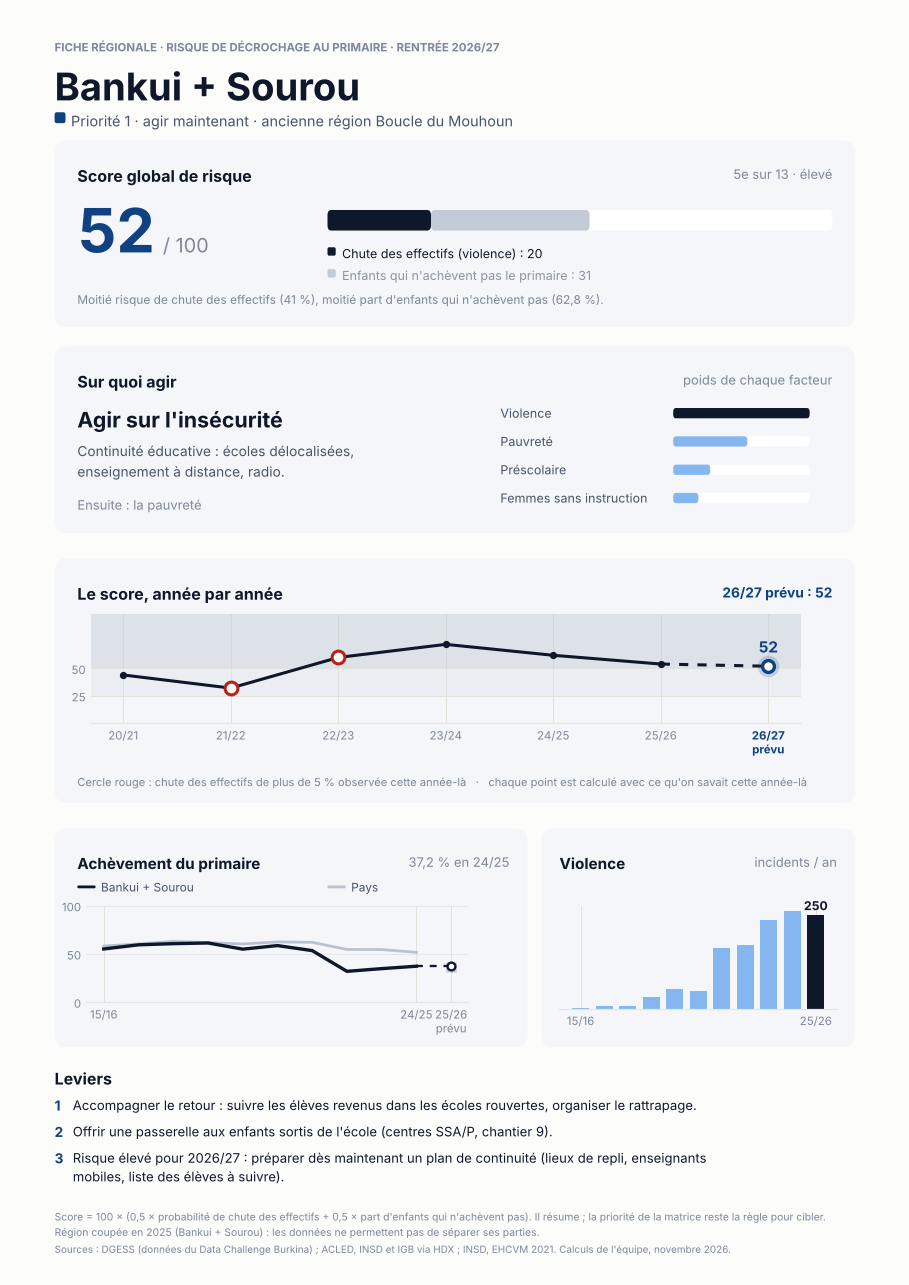

analyse/fiches/fiche_djoro.png


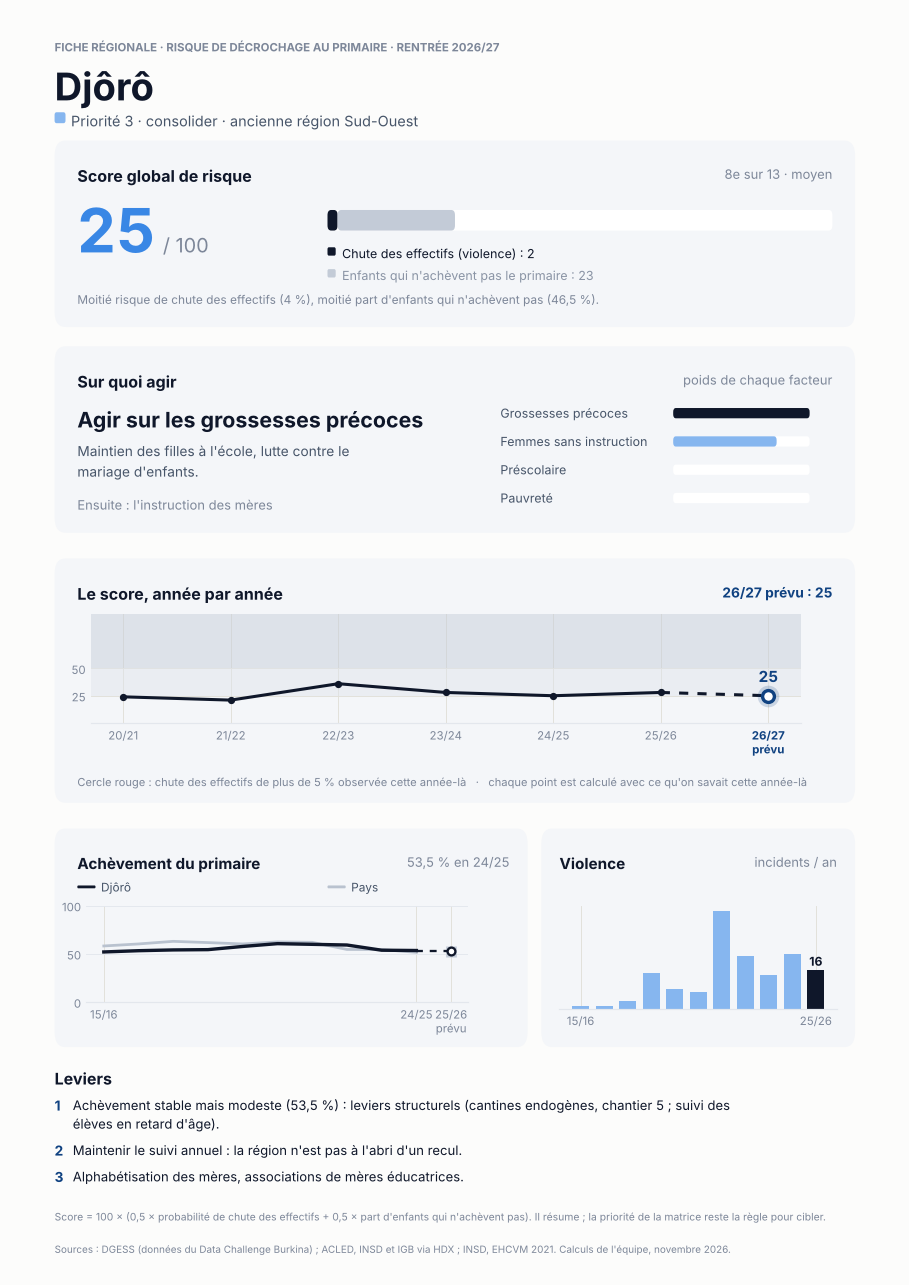

analyse/fiches/fiche_goulmousirbatapoa.png


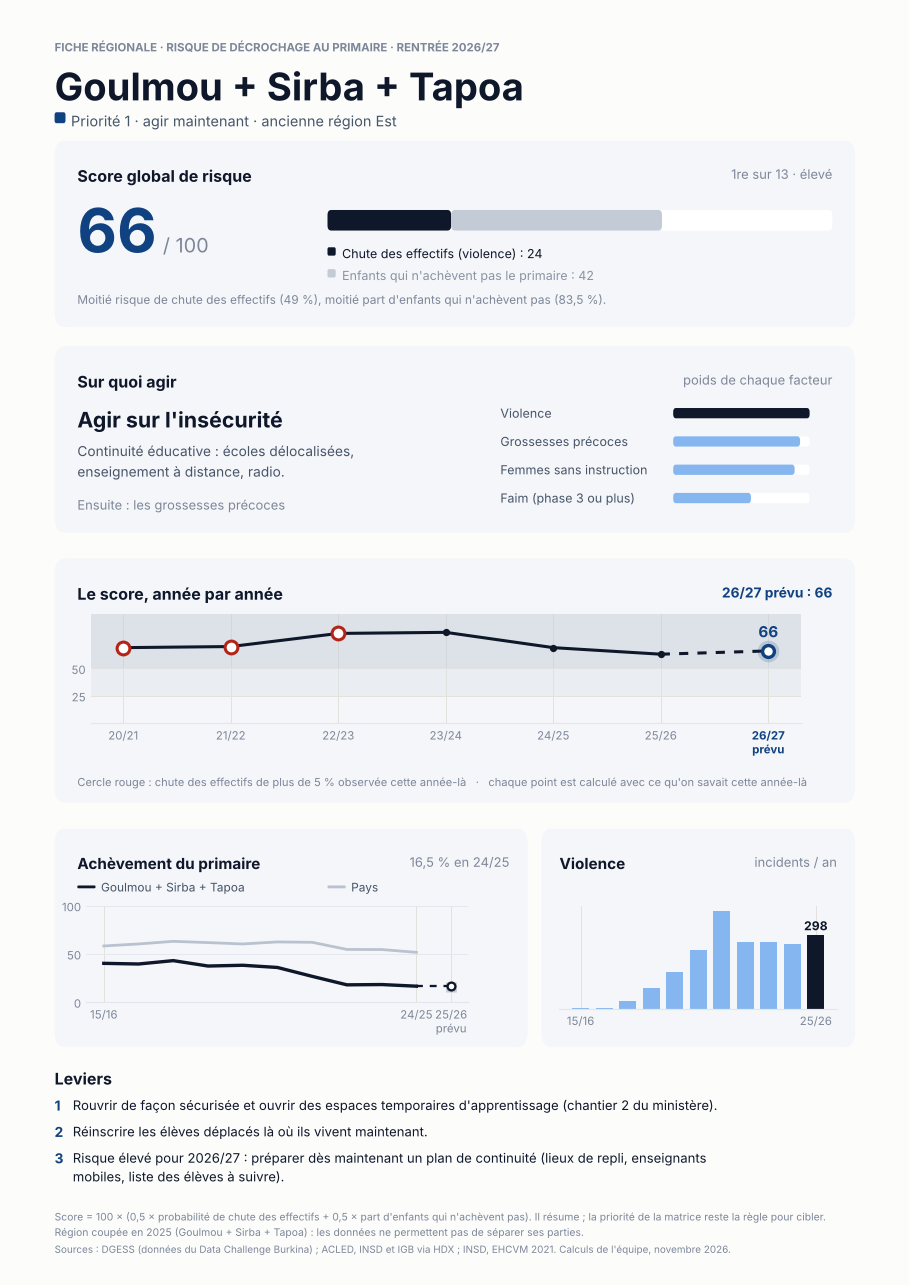

analyse/fiches/fiche_guiriko.png


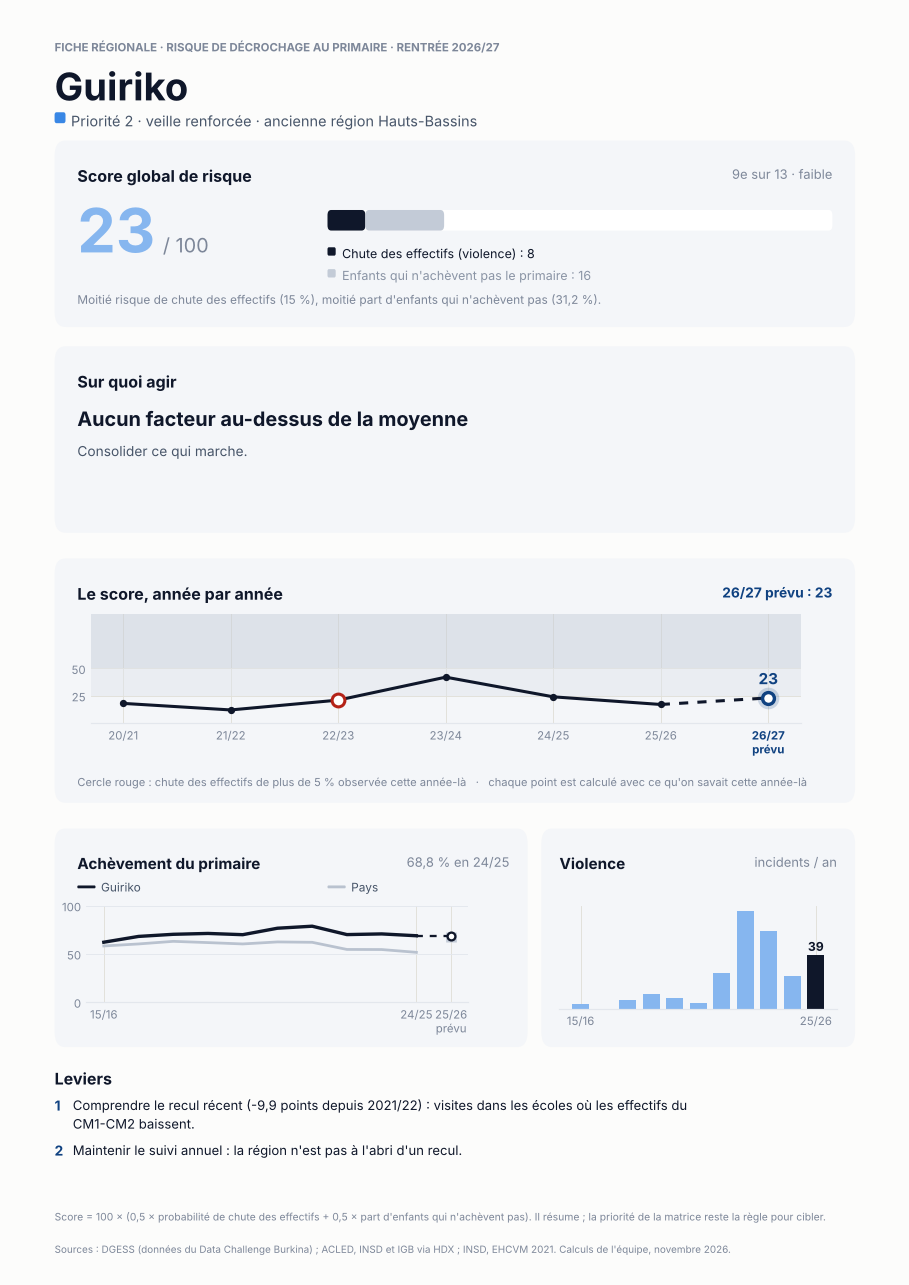

analyse/fiches/fiche_kadiogo.png


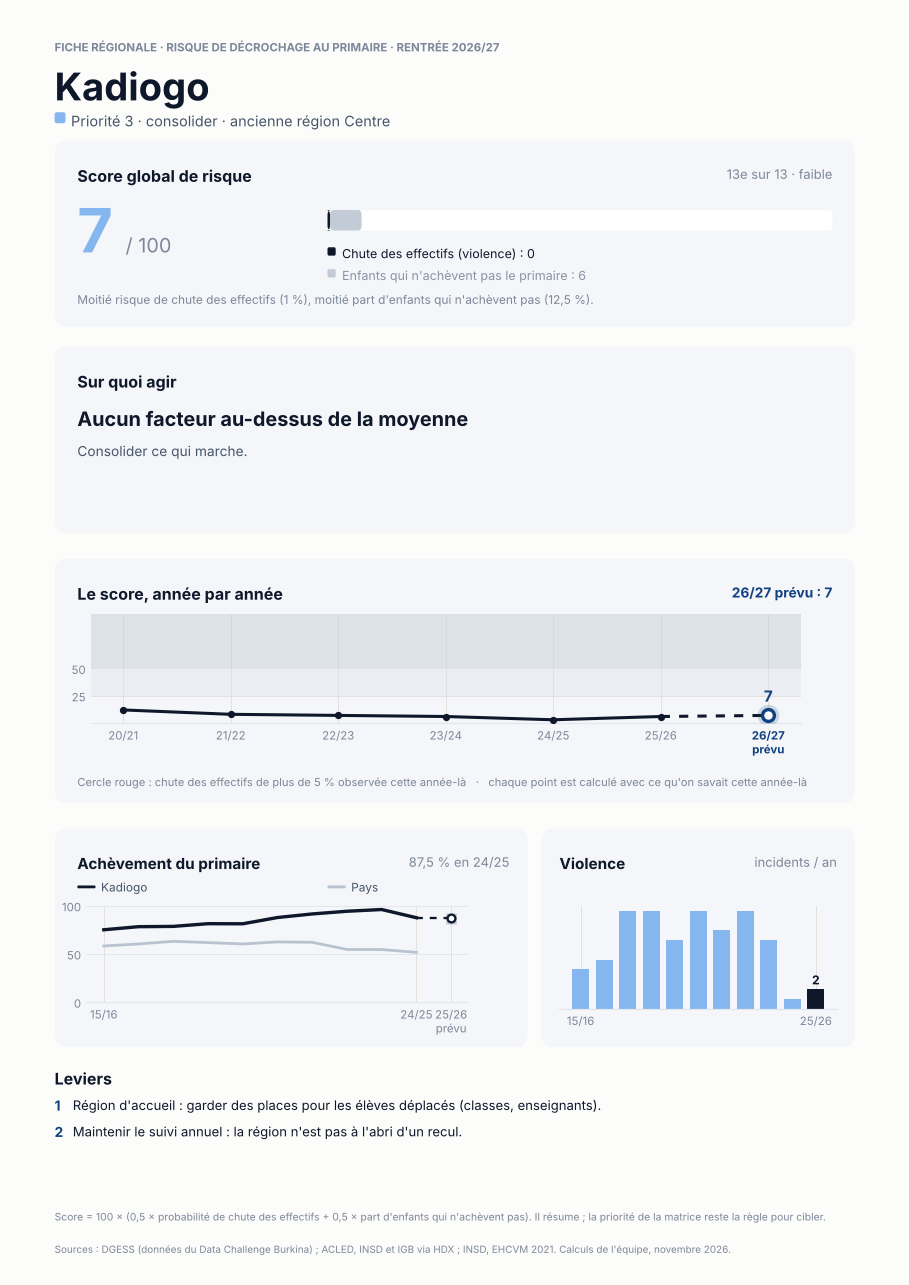

analyse/fiches/fiche_koulse.png


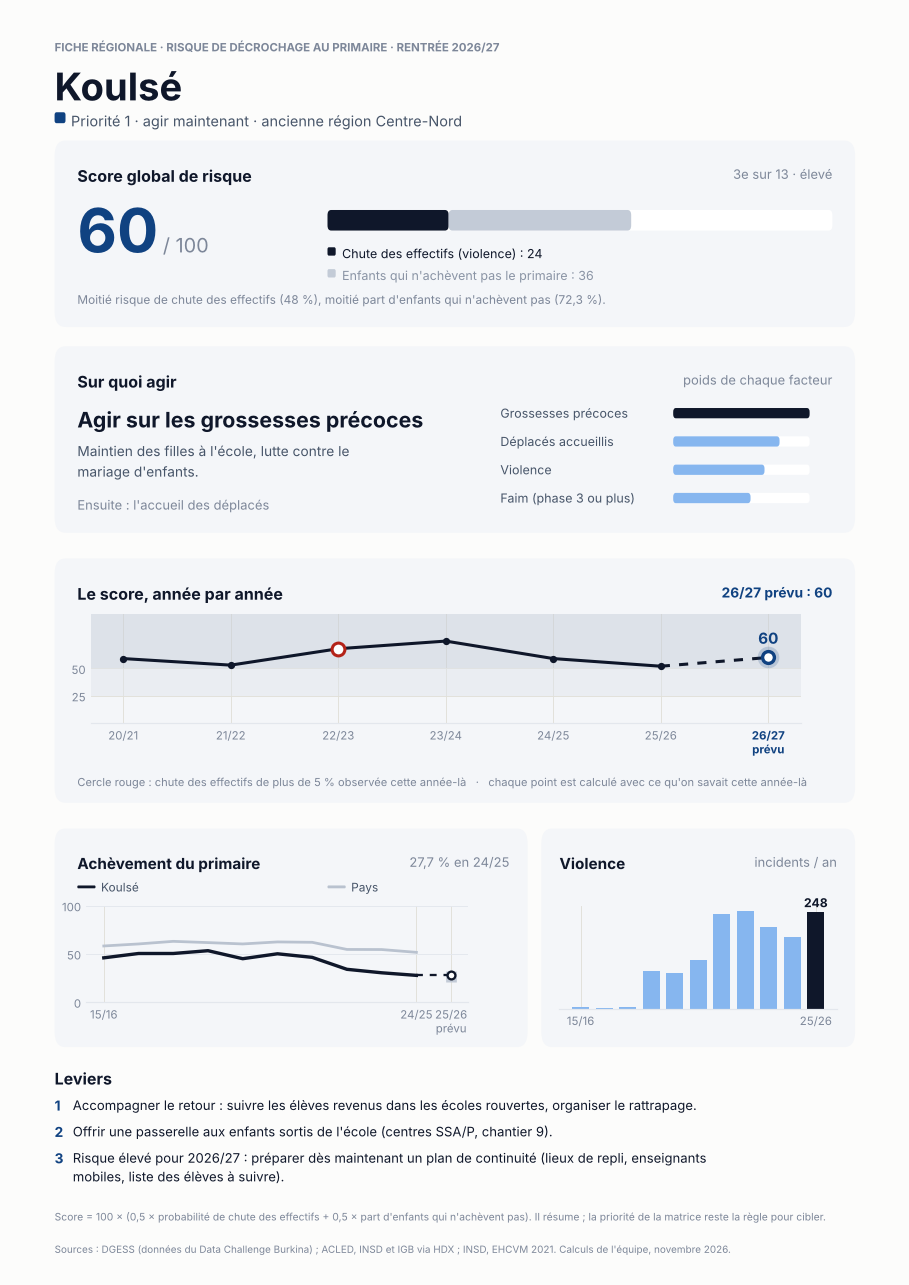

In [39]:
lancer_fiches_regionales = main
t0 = time.time()
sys.argv = ['fiches_regionales.py']
lancer_fiches_regionales()
montrer_figures(t0)